# Semana 8: Segmentación de clientes con K-Means
**Materia:** Aprendizaje Automático, Centro Politécnico Superior Malvinas Argentinas  |  **Alumno:** Tomás Roa Gunn

**Objetivo:** descubrir cuántos segmentos de clientes existen a partir de su comportamiento de compra y de uso del sitio, sin etiquetas previas.

**Plan de trabajo**
1. Cargar y explorar el dataset.
2. Escalar las variables.
3. Comparar k = 2 a 6 con el método del codo (y la silueta como segunda opinión).
4. Elegir k y entrenar K-Means.
5. Describir el perfil de cada segmento a partir de sus centroides.

## 1. Datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
SEED = 42

df = pd.read_csv("../Datos/dataset_segmentacion_clientes.csv")
print(df.shape)
df.head()

(700, 7)


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522


In [2]:
print("Valores nulos:", df.isna().sum().sum(), "| Filas duplicadas:", df.duplicated().sum())
df.describe().T.round(2)

Valores nulos: 0 | Filas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
purchase_freq_month,700.0,5.88,4.47,0.10,2.28,4.13,11.21,14.60
avg_basket_usd,700.0,248.17,154.90,86.99,90.77,180.22,449.72,452.97
time_on_site_min,700.0,16.78,12.91,3.16,6.60,9.97,34.34,38.35
discount_sensitivity,700.0,0.43,0.43,0.00,0.00,0.30,1.00,1.00
returns_rate,700.0,0.34,0.36,0.00,0.00,0.17,0.80,0.80
noise_gauss,700.0,0.02,1.01,-3.57,-0.65,0.08,0.73,2.86
noise_uniform,700.0,-0.01,1.68,-2.99,-1.42,0.01,1.41,3.00


El dataset tiene **700 clientes** y siete columnas. Cinco son las que describe la consigna:

| Variable | Qué mide |
|---|---|
| `purchase_freq_month` | Compras por mes |
| `avg_basket_usd` | Ticket promedio por compra (USD) |
| `time_on_site_min` | Minutos de permanencia en el sitio |
| `discount_sensitivity` | Sensibilidad a descuentos (0 a 1) |
| `returns_rate` | Tasa de devoluciones (hasta 0,8) |

Las otras dos, `noise_gauss` y `noise_uniform`, **no figuran en la consigna** y parecen ser ruido agregado a propósito. Lo compruebo antes de descartarlas.

In [3]:
cols = ["purchase_freq_month", "avg_basket_usd", "time_on_site_min", "discount_sensitivity", "returns_rate"]
ruido = ["noise_gauss", "noise_uniform"]
df[cols + ruido].corr().loc[ruido, cols].round(2)

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
noise_gauss,0.01,0.03,0.01,-0.01,-0.05
noise_uniform,-0.02,0.06,-0.02,-0.04,0.01


Las dos columnas de ruido tienen correlación prácticamente nula con las cinco variables reales, así que no aportan información sobre el comportamiento de los clientes. **Las excluyo del modelo**: si las incluyera, solo agregarían ruido a las distancias.

### Distribución de las variables

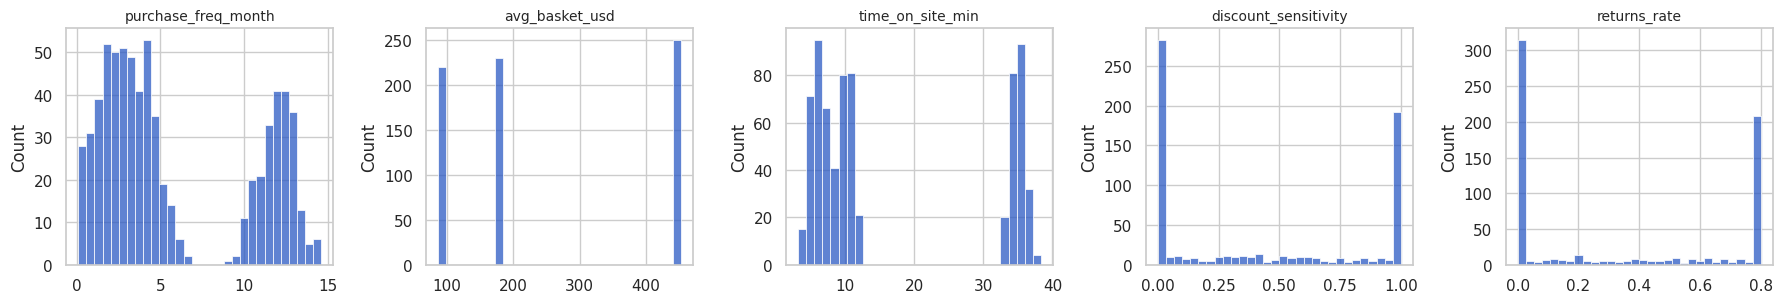

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, c in zip(axes, cols):
    sns.histplot(df[c], bins=30, ax=ax, color="#2B59C3")
    ax.set_title(c, fontsize=10); ax.set_xlabel("")
plt.tight_layout(); plt.show()

Tres cosas se ven a simple vista:
- `avg_basket_usd` se concentra en tres valores (cerca de 90, 180 y 450 USD). Eso ya sugiere **tres perfiles de compra**.
- `discount_sensitivity` y `returns_rate` se acumulan en los extremos (0 y 1; 0 y 0,8), porque están acotadas.
- Las escalas son muy distintas: el ticket llega a ~450 y la sensibilidad a descuentos nunca pasa de 1.

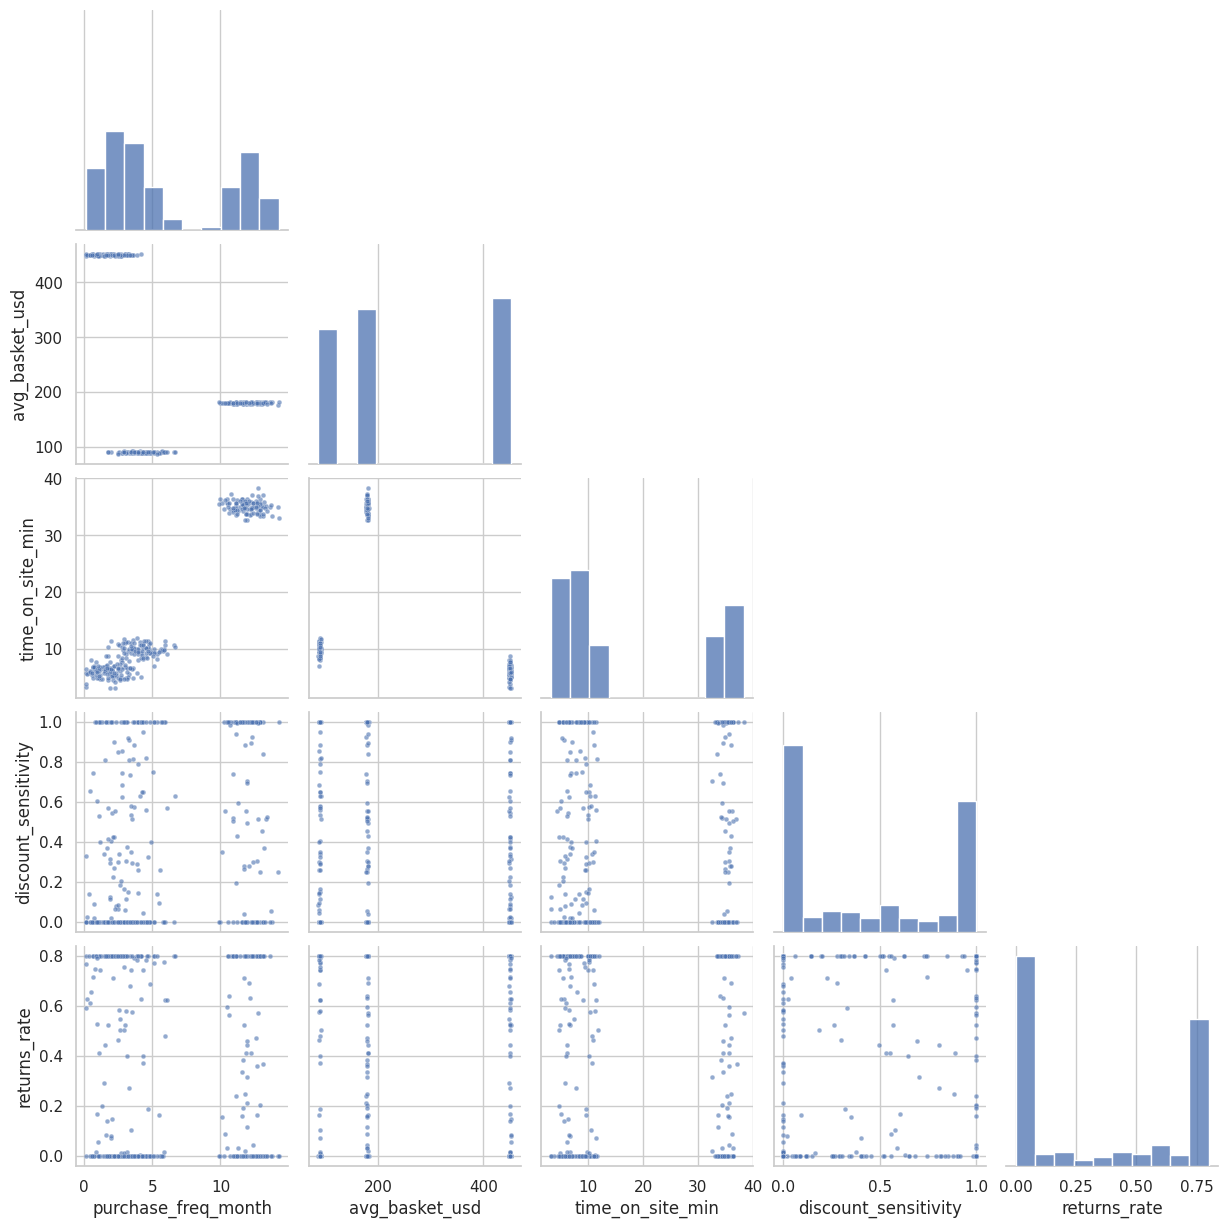

In [5]:
sns.pairplot(df[cols].sample(300, random_state=SEED), corner=True, plot_kws={"s": 12, "alpha": 0.6})
plt.show()

## 2. Escalado
K-Means usa distancias, así que una variable con números grandes (el ticket, en cientos de dólares) dominaría a una con números chicos (la sensibilidad a descuentos, entre 0 y 1). Estandarizo las cinco variables: media 0 y desvío 1.

In [6]:
scaler = StandardScaler()
X = scaler.fit_transform(df[cols])
pd.DataFrame(X, columns=cols).describe().loc[["mean", "std"]].round(2)

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
mean,-0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0


## 3. ¿Cuántos grupos? Método del codo, k = 2 a 6
Para cada k entreno K-Means y guardo la **inercia** (suma de las distancias al cuadrado de cada cliente a su centroide). Siempre baja al aumentar k, así que busco el punto donde la mejora deja de ser grande. Como segunda opinión calculo el **coeficiente de silueta** (cuanto más alto, mejor separados están los grupos).

In [7]:
ks = range(2, 7)
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(X)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(X, km.labels_))

resumen = pd.DataFrame({"k": list(ks), "inercia": np.round(inercia, 1), "silueta": np.round(silueta, 3)})
resumen["mejora_inercia_%"] = (-pd.Series(inercia).pct_change() * 100).round(1)
resumen

,k,inercia,silueta,mejora_inercia_%
0,2,2088.9,0.400,NaN
1,3,1408.7,0.431,32.6
2,4,1173.4,0.429,16.7
3,5,997.7,0.420,15.0
4,6,762.5,0.461,23.6


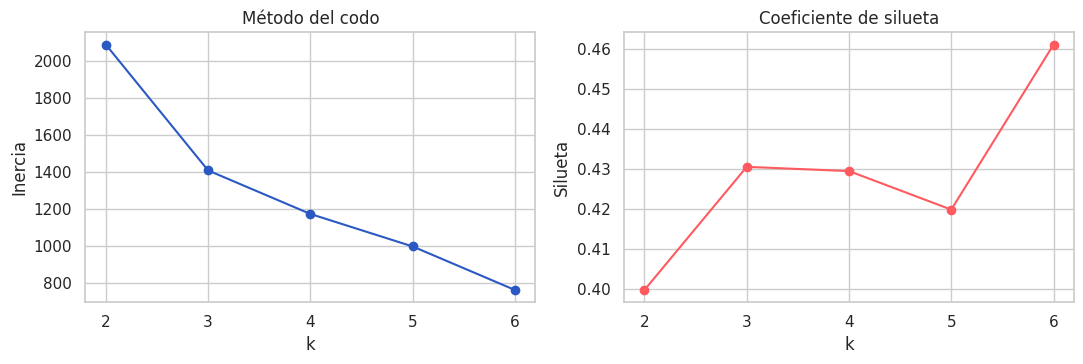

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(list(ks), inercia, "o-", color="#2B59C3"); ax[0].set_title("Método del codo"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inercia")
ax[1].plot(list(ks), silueta, "o-", color="#FF5A5F"); ax[1].set_title("Coeficiente de silueta"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silueta")
for a in ax: a.set_xticks(list(ks))
plt.tight_layout(); plt.show()

**Lectura de los dos gráficos**
- La inercia cae mucho entre k=2 y k=3, y sigue bajando sin un codo bien marcado. Con cinco variables, parte de la caída viene de que las dos variables acotadas (`discount_sensitivity` y `returns_rate`) permiten dividir cada grupo en subgrupos.
- La silueta es la más alta en **k = 6** (0,46), por encima de k=3 (0,43).

Antes de decidir miro qué hay detrás de k=3 y k=6, porque un número no sirve si los grupos no se pueden explicar.

### ¿Qué pasa si miro solo las tres variables de comportamiento?

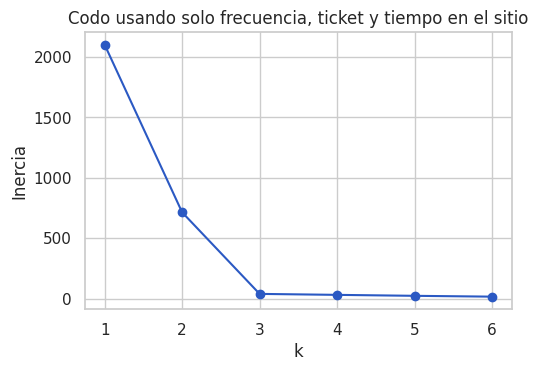

[2100.0, 713.9, 39.4, 31.5, 23.5, 16.7]


In [9]:
X3 = StandardScaler().fit_transform(df[["purchase_freq_month", "avg_basket_usd", "time_on_site_min"]])
inercia3 = [KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X3).inertia_ for k in range(1, 7)]
plt.figure(figsize=(5.5, 3.6))
plt.plot(range(1, 7), inercia3, "o-", color="#2B59C3")
plt.title("Codo usando solo frecuencia, ticket y tiempo en el sitio"); plt.xlabel("k"); plt.ylabel("Inercia"); plt.show()
print([round(i, 1) for i in inercia3])

Con solo frecuencia, ticket y tiempo en el sitio, el codo es clarísimo en **k = 3**: la inercia pasa de ~714 (k=2) a ~39 (k=3) y después casi no mejora. Es decir, hay **tres perfiles de compra** muy definidos. Las otras dos variables (sensibilidad a descuentos y devoluciones) son las que dividen cada perfil en subgrupos.

## 4. Elección de k
Comparo los dos candidatos con sus centroides en unidades originales (USD, minutos, etc.).

In [10]:
def perfil(k):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(X)
    out = df[cols].copy(); out["cluster"] = km.labels_
    tabla = out.groupby("cluster")[cols].mean().round(2)
    tabla["clientes"] = out.groupby("cluster").size()
    return tabla

print("k = 3"); display(perfil(3))
print("k = 6"); display(perfil(6))

# Dispersión interna de las dos variables acotadas dentro de cada grupo de k=3
km3 = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=SEED).fit(X)
print("Desvío interno con k = 3"); display(df.assign(cluster=km3.labels_).groupby("cluster")[["discount_sensitivity", "returns_rate"]].std().round(2))

k = 3


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,clientes
cluster,,,,,,
0,11.96,180.00,35.02,0.54,0.33,230
1,1.85,450.12,5.97,0.36,0.38,250
2,4.09,89.96,10.00,0.38,0.30,220


k = 6


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,clientes
cluster,,,,,,
0,4.01,90.01,9.97,0.40,0.03,136
1,11.95,179.99,35.13,0.11,0.35,110
2,1.88,450.19,5.87,0.36,0.04,128
3,1.81,450.05,6.08,0.35,0.73,122
4,11.97,180.00,34.92,0.93,0.31,120
5,4.23,89.88,10.05,0.35,0.73,84


Desvío interno con k = 3


,discount_sensitivity,returns_rate
cluster,,
0,0.44,0.35
1,0.41,0.36
2,0.42,0.35


- **k = 3** separa los tres perfiles de compra, pero mezcla dentro de cada uno a clientes muy distintos en devoluciones y en sensibilidad a descuentos. El desvío de esas dos variables dentro de cada grupo es alto (ver tabla de dispersión interna).
- **k = 6** divide cada perfil de compra según devoluciones (casi nulas vs. muy altas) y, en el perfil de compra frecuente, según sensibilidad a descuentos (muy baja vs. muy alta). Cada grupo se puede explicar con una frase, que es lo que pide la consigna, y tiene la mejor silueta del rango.

**Elijo k = 6** como segmentación final, y uso k=3 como lectura general: los seis segmentos son subgrupos de tres perfiles de compra.

## 5. Modelo final: K-Means con k = 6

In [11]:
K = 6
km = KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=SEED).fit(X)
df["cluster_raw"] = km.labels_

# Ordeno los segmentos de forma reproducible: primero por tramo de ticket, luego por devoluciones
cent = df.groupby("cluster_raw")[cols].mean()
cent["tramo"] = pd.cut(cent["avg_basket_usd"], [0, 135, 315, 1000], labels=[0, 1, 2]).astype(int)
orden = cent.sort_values(["tramo", "returns_rate"]).index.tolist()
letras = dict(zip(orden, list("ABCDEF")))
df["segmento"] = df["cluster_raw"].map(letras)

print("Silueta:", round(silhouette_score(X, km.labels_), 3), "| Inercia:", round(km.inertia_, 1))
df["segmento"].value_counts().sort_index()

Silueta: 0.461 | Inercia: 762.5


segmento
A    136
B     84
C    120
D    110
E    128
F    122
Name: count, dtype: int64

### Centroides (promedio de cada segmento, en unidades originales)

In [12]:
centroides = df.groupby("segmento")[cols].mean().round(2)
centroides["clientes"] = df.groupby("segmento").size()
centroides["% del total"] = (centroides["clientes"] / len(df) * 100).round(1)
centroides

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,clientes,% del total
segmento,,,,,,,
A,4.01,90.01,9.97,0.40,0.03,136,19.4
B,4.23,89.88,10.05,0.35,0.73,84,12.0
C,11.97,180.00,34.92,0.93,0.31,120,17.1
D,11.95,179.99,35.13,0.11,0.35,110,15.7
E,1.88,450.19,5.87,0.36,0.04,128,18.3
F,1.81,450.05,6.08,0.35,0.73,122,17.4


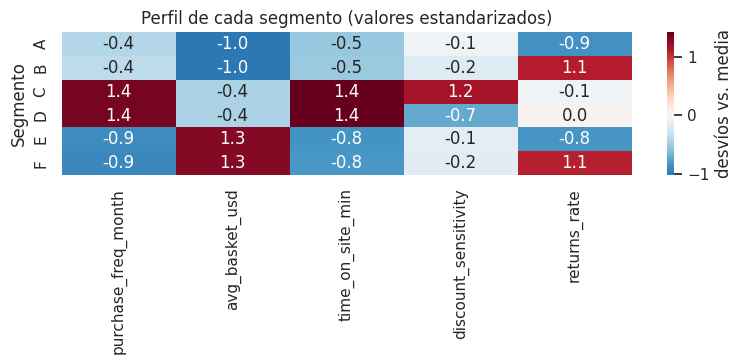

In [13]:
# Mapa de calor con los centroides estandarizados, para comparar variables entre sí
z = pd.DataFrame(scaler.transform(df.groupby("segmento")[cols].mean()), index=sorted(df["segmento"].unique()), columns=cols)
plt.figure(figsize=(8, 3.8))
sns.heatmap(z, annot=True, fmt=".1f", cmap="RdBu_r", center=0, cbar_kws={"label": "desvíos vs. media"})
plt.title("Perfil de cada segmento (valores estandarizados)"); plt.ylabel("Segmento"); plt.tight_layout(); plt.show()

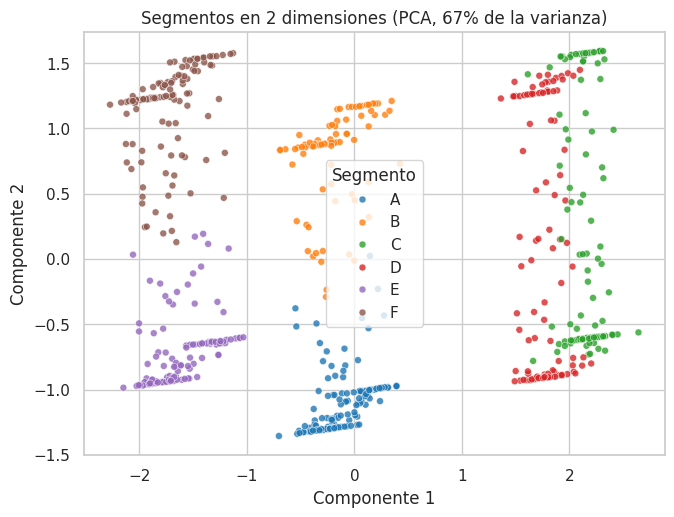

In [14]:
pca = PCA(n_components=2, random_state=SEED)
P = pca.fit_transform(X)
plt.figure(figsize=(7.5, 5.5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df["segmento"], hue_order=list("ABCDEF"), palette="tab10", s=25, alpha=0.8)
plt.title(f"Segmentos en 2 dimensiones (PCA, {pca.explained_variance_ratio_.sum():.0%} de la varianza)")
plt.xlabel("Componente 1"); plt.ylabel("Componente 2"); plt.legend(title="Segmento"); plt.show()

## 6. Perfil de cada segmento
Los valores salen de la tabla de centroides de arriba.

| Segmento | Compras/mes | Ticket (USD) | Minutos en sitio | Sensib. a descuentos | Devoluciones | Perfil |
|---|---|---|---|---|---|---|
| **A** | ~4 | ~90 | ~10 | ~0,40 | ~0,03 | **Ticket bajo, casi no devuelven.** Compradores moderados y fiables. |
| **B** | ~4 | ~90 | ~10 | ~0,35 | ~0,73 | **Ticket bajo, devuelven mucho.** Compran poco y devuelven la mayoría. |
| **C** | ~12 | ~180 | ~35 | ~0,93 | ~0,31 | **Frecuentes y muy sensibles a descuentos.** Foco para promociones. |
| **D** | ~12 | ~180 | ~35 | ~0,11 | ~0,35 | **Frecuentes y poco sensibles a descuentos.** Compran seguido sin necesitar oferta. |
| **E** | ~2 | ~450 | ~6 | ~0,36 | ~0,04 | **Compras esporádicas, grandes y sin devoluciones.** Foco en upselling premium. |
| **F** | ~2 | ~450 | ~6 | ~0,35 | ~0,73 | **Compras esporádicas, grandes y con muchas devoluciones.** Revisar causas (talles, expectativas, fraude). |

**Cómo se relaciona con los patrones que pedía la consigna**
- *Frecuencia alta, ticket bajo y mucha sensibilidad a descuentos:* en estos datos la frecuencia alta viene con ticket medio (~180 USD), no bajo. El segmento **C** es el que más se acerca: compra seguido y reacciona a los descuentos.
- *Frecuencia baja, ticket alto y baja sensibilidad:* son **E** y **F** (compras esporádicas de ~450 USD).
- *Tiempo en el sitio y devoluciones diferenciados:* los segmentos que más exploran (C y D, ~35 min) devuelven un nivel intermedio. Los que más devuelven (B y F, ~0,73) pasan poco tiempo en el sitio (6 a 10 minutos), es decir, **exploran poco y devuelven mucho**, lo contrario de la hipótesis de la consigna.

In [15]:
# Compruebo que la tabla de perfiles de arriba coincide con los centroides calculados
esperado = {"A": (4, 90, 10, 0.40, 0.03), "B": (4, 90, 10, 0.35, 0.73), "C": (12, 180, 35, 0.93, 0.31),
            "D": (12, 180, 35, 0.11, 0.35), "E": (2, 450, 6, 0.36, 0.04), "F": (2, 450, 6, 0.35, 0.73)}
for s, v in esperado.items():
    real = centroides.loc[s, cols].values
    ok = np.allclose(real, v, atol=[0.5, 5, 1.5, 0.08, 0.05])
    print(s, "OK" if ok else f"REVISAR: {real.round(2)}")

A OK
B OK
C OK
D OK
E OK
F OK


## 7. Conclusiones
1. **Hay seis segmentos de clientes**, que se explican como tres perfiles de compra (ticket de ~90, ~180 y ~450 USD) divididos por devoluciones y por sensibilidad a descuentos.
2. **El método del codo, por sí solo, no alcanza** con las cinco variables: la inercia baja de forma gradual. Con solo las tres variables de comportamiento el codo es evidente en k=3. La silueta (máxima en k=6) y la posibilidad de describir cada grupo me llevaron a elegir k=6.
3. **Accionables por segmento:** promociones para el segmento C, upselling premium para E, y revisar el proceso de devoluciones en B y F, que son los que más devuelven.
4. **Qué dejé afuera y por qué:** `noise_gauss` y `noise_uniform`, sin correlación con las demás variables.

**Limitaciones**
- `discount_sensitivity` y `returns_rate` están acotadas y acumuladas en los extremos (0 y 1; 0 y 0,8), algo que K-Means, que asume grupos redondeados, maneja de forma imperfecta.
- La silueta de 0,46 es moderada: los segmentos están diferenciados pero no perfectamente separados.
- Es un dataset de 700 clientes, probablemente sintético (por el ruido agregado y los valores tan regulares), así que las conclusiones sirven como ejercicio y no como hallazgos de un negocio real.